# 01 — Dataset Exploration

## 1. Research Objectives

This notebook performs an exploratory analysis of the 20 Newsgroups
dataset used in the TopicSense-NLP supervised multi-class text
classification project.

The objectives are to:

1. Understand the dataset's structure, size, and class distribution.
2. Examine the distribution of document lengths.
3. Investigate vocabulary characteristics and frequently occurring terms.
4. Inspect representative documents from different classes.
5. Examine dataset integrity, duplicate content, and train-test
   contamination risks.
6. Establish evidence-based considerations for subsequent preprocessing
   and model development.

## 2. Dataset Description

The primary dataset is the 20 Newsgroups corpus, containing documents
collected from 20 Usenet discussion groups.

Each document is associated with a newsgroup label. The classification
task is therefore formulated as supervised multi-class text
classification.

The original training and test partitions are preserved.

## 3. Exploratory Methodology

The analysis examines:

- Dataset dimensions and metadata.
- Class frequencies and class imbalance.
- Document lengths in characters and words.
- Vocabulary size and document frequency.
- Representative document samples.
- Exact duplicate and near-duplicate content.
- Potential overlap between training and test partitions.

No learned preprocessing transformations are applied in this notebook.
The original raw documents remain unchanged.

All findings are based on observed dataset values rather than assumed
or predetermined outcomes.

In [1]:
from __future__ import annotations

import json
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", RANDOM_SEED)

Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
NumPy version: 2.5.5
Pandas version: 3.1.1
Random seed: 42


## 4. Project Paths

The notebook uses paths relative to the project root. This allows it
to run whether JupyterLab was launched from the project root or the
notebooks directory.

In [2]:
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )

RAW_DATA_PATH = (
    PROJECT_ROOT
    / "data/raw/20newsgroups/20newsgroups_raw.jsonl"
)

DATASET_MANIFEST_PATH = (
    PROJECT_ROOT
    / "data/raw/20newsgroups/20newsgroups_manifest.json"
)

LEAKAGE_REPORT_PATH = (
    PROJECT_ROOT
    / "results/logs/dataset_leakage_analysis.json"
)

BODY_AUDIT_PATH = (
    PROJECT_ROOT
    / "results/logs/dataset_body_duplicate_audit.json"
)

CONTAMINATION_MANIFEST_PATH = (
    PROJECT_ROOT
    / "data/interim/20newsgroups/contamination_manifest.json"
)

print("Project root:", PROJECT_ROOT)
print("Raw dataset exists:", RAW_DATA_PATH.exists())
print("Dataset manifest exists:", DATASET_MANIFEST_PATH.exists())
print("Leakage report exists:", LEAKAGE_REPORT_PATH.exists())
print("Body audit exists:", BODY_AUDIT_PATH.exists())
print(
    "Contamination manifest exists:",
    CONTAMINATION_MANIFEST_PATH.exists(),
)

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Raw dataset exists: True
Dataset manifest exists: True
Leakage report exists: True
Body audit exists: True
Contamination manifest exists: True


## 5. Dataset Loading

The raw JSONL dataset is loaded into a pandas DataFrame.

Each row represents one document. The original record identifier,
source partition, class label, and document text are retained.

The dataset is loaded without modifying the original documents.

In [3]:
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(RAW_DATA_PATH)

df = pd.read_json(
    RAW_DATA_PATH,
    lines=True,
    encoding="utf-8",
)

required_columns = {
    "record_id",
    "source_split",
    "label",
    "text",
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing_columns)}"
    )

print("Dataset loaded successfully.")
print("Number of documents:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

Dataset loaded successfully.
Number of documents: 18846
Number of columns: 7


,record_id,dataset,source_split,text,label,label_id,content_sha256
0,20newsgroups-train-00000,20newsgroups,train,From: cubbie@garnet.berkeley.edu ( )\nSubject: Re: Cubs behind Mar...,rec.sport.baseball,9,80acf4c7027ef650f0eed347052470ec7c295027fe3a788ca629ad3217f8fb5b
1,20newsgroups-train-00001,20newsgroups,train,From: gnelson@pion.rutgers.edu (Gregory Nelson)\nSubject: Thanks Apple: Free Ethernet on my C610...,comp.sys.mac.hardware,4,da00ca13356a8798c20b7ef7d0eafd1804867048399dd06e3d675a2a16a694d8
2,20newsgroups-train-00002,20newsgroups,train,From: crypt-comments@math.ncsu.edu\nSubject: Cryptography FAQ 10/10 - References\nOrganization: ...,sci.crypt,11,018e9ecd1a200c76e15e372b7cef2da78f813e0205b9243986e856dadd96e83f
3,20newsgroups-train-00003,20newsgroups,train,From: ()\nSubject: Re: Quadra SCSI Problems???\nOrganization: Apple Computer Inc.\nLines: 28\n\...,comp.sys.mac.hardware,4,66d0677740566cad12556f6826f96ba429e4fd2e55210a1b1eb97eb68a117c4c
4,20newsgroups-train-00004,20newsgroups,train,From: keith@cco.caltech.edu (Keith Allan Schneider)\nSubject: Re: <Political Atheists?\nOrganiza...,alt.atheism,0,e4f6369620427253de1bf3d8c7daa07280b1031336264f670877657b0bd3f8a4


In [4]:
with DATASET_MANIFEST_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    dataset_manifest = json.load(file)

print(json.dumps(dataset_manifest, indent=2)[:5000])

{
  "dataset": "20newsgroups",
  "display_name": "20 Newsgroups",
  "source_url": "https://people.csail.mit.edu/jrennie/20Newsgroups/",
  "retrieval_method": "sklearn.datasets.fetch_20newsgroups",
  "retrieved_at_utc": "2026-11-24T16:49:49.738987+00:00",
  "scikit_learn_version": "1.9.1",
  "total_documents": 18846,
  "number_of_classes": 20,
  "target_names": [
    "alt.atheism",
    "comp.graphics",
    "comp.os.ms-windows.misc",
    "comp.sys.ibm.pc.hardware",
    "comp.sys.mac.hardware",
    "comp.windows.x",
    "misc.forsale",
    "rec.autos",
    "rec.motorcycles",
    "rec.sport.baseball",
    "rec.sport.hockey",
    "sci.crypt",
    "sci.electronics",
    "sci.med",
    "sci.space",
    "soc.religion.christian",
    "talk.politics.guns",
    "talk.politics.mideast",
    "talk.politics.misc",
    "talk.religion.misc"
  ],
  "source_split_counts": {
    "train": 11314,
    "test": 7532
  },
  "class_distribution": {
    "train": {
      "rec.sport.baseball": 597,
      "comp.sys

## 6. Dataset Structure

This section examines the dataset's dimensions, field types, missing
values, duplicate identifiers, class labels, and official partitions.

These checks provide an initial understanding of the dataset before
statistical analysis.

In [5]:
print("Dataset dimensions:", df.shape)

print("\nColumn data types:")
display(df.dtypes.to_frame("data_type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate record identifiers:")
print(df["record_id"].duplicated().sum())

print("\nUnique classes:")
print(df["label"].nunique())

print("\nClasses:")
print(sorted(df["label"].dropna().unique()))

print("\nSource partitions:")
display(df["source_split"].value_counts().to_frame("documents"))

Dataset dimensions: (18846, 7)

Column data types:


,data_type
record_id,str
dataset,str
source_split,str
text,str
label,str
label_id,int64
content_sha256,str



Missing values:


,missing_values
record_id,0
dataset,0
source_split,0
text,0
label,0
label_id,0
content_sha256,0



Duplicate record identifiers:
0

Unique classes:
20

Classes:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Source partitions:


,documents
source_split,
train,11314
test,7532


### What the Dataset Structure Tells Us

The dataset contains **18,846 documents across 20 newsgroup classes**. The original training partition contains 11,314 documents, while the test partition contains 7,532.

The structural checks found no missing values in the seven dataset fields, no duplicate record identifiers, and no unexpected source partitions. All records have a label and document text.

This is a sound starting point for supervised classification. Each document has an identifiable class and an existing partition, so the project can preserve the benchmark's original evaluation structure rather than creating an entirely new split.

It is worth distinguishing structural validity from content quality. A record can have a valid identifier, label, and text field while still containing quoted messages, repeated content, irrelevant material, or ambiguous topic information. Those questions require the subsequent analyses in this notebook.

In [6]:
partition_label_counts = pd.crosstab(
    df["label"],
    df["source_split"],
)

display(partition_label_counts)

assert set(df["source_split"].unique()) == {"train", "test"}
assert df["record_id"].is_unique
assert df["label"].notna().all()
assert df["text"].notna().all()

print("Structural validation checks passed.")

source_split,test,train
label,,
alt.atheism,319,480
comp.graphics,389,584
comp.os.ms-windows.misc,394,591
comp.sys.ibm.pc.hardware,392,590
comp.sys.mac.hardware,385,578
comp.windows.x,395,593
misc.forsale,390,585
rec.autos,396,594
rec.motorcycles,398,598


Structural validation checks passed.


## 7. Class Distribution

Class distribution is important in supervised classification because
imbalanced datasets can influence model learning and evaluation.

We examine the frequency and relative proportion of each class,
separately for the training and test partitions.

Macro-averaged F1 will be particularly useful later because it gives
each class equal importance regardless of its frequency.

In [7]:
class_distribution = (
    df.groupby(["source_split", "label"])
    .size()
    .unstack(fill_value=0)
)

class_distribution = class_distribution.T

class_distribution["total"] = (
    class_distribution["train"]
    + class_distribution["test"]
)

class_distribution["train_percentage"] = (
    class_distribution["train"]
    / class_distribution["train"].sum()
    * 100
)

class_distribution["test_percentage"] = (
    class_distribution["test"]
    / class_distribution["test"].sum()
    * 100
)

display(
    class_distribution.sort_values(
        "total",
        ascending=False,
    ).round(2)
)

source_split,test,train,total,train_percentage,test_percentage
label,,,,,
rec.sport.hockey,399,600,999,5.30,5.30
soc.religion.christian,398,599,997,5.29,5.28
rec.motorcycles,398,598,996,5.29,5.28
rec.sport.baseball,397,597,994,5.28,5.27
sci.crypt,396,595,991,5.26,5.26
rec.autos,396,594,990,5.25,5.26
sci.med,396,594,990,5.25,5.26
comp.windows.x,395,593,988,5.24,5.24
sci.space,394,593,987,5.24,5.23


### Interpreting the Class Distribution

The class distribution is relatively balanced, although the classes are not identical in size.

The training partition ranges from 377 documents in `talk.religion.misc` to 600 in `rec.sport.hockey`. The resulting largest-to-smallest class ratio is approximately **1.59:1**.

The test partition follows a very similar distribution. Each class accounts for approximately 3.33% to 5.30% of the test documents. The corresponding training proportions are also closely aligned.

This is encouraging for model evaluation. No single class dominates the dataset, and the training and test partitions have comparable class proportions. We therefore have no immediate evidence of a severe class imbalance problem.

That does not make class-level evaluation unnecessary. A model may perform well on the larger classes while struggling with smaller or more ambiguous ones. Accuracy alone could conceal that difference. We will therefore retain macro-averaged F1 and per-class precision, recall, and F1 as important evaluation measures.

At this stage, there is no compelling reason to apply class weighting automatically. It should be considered as an experiment and justified by measured model performance rather than assumed to be necessary.

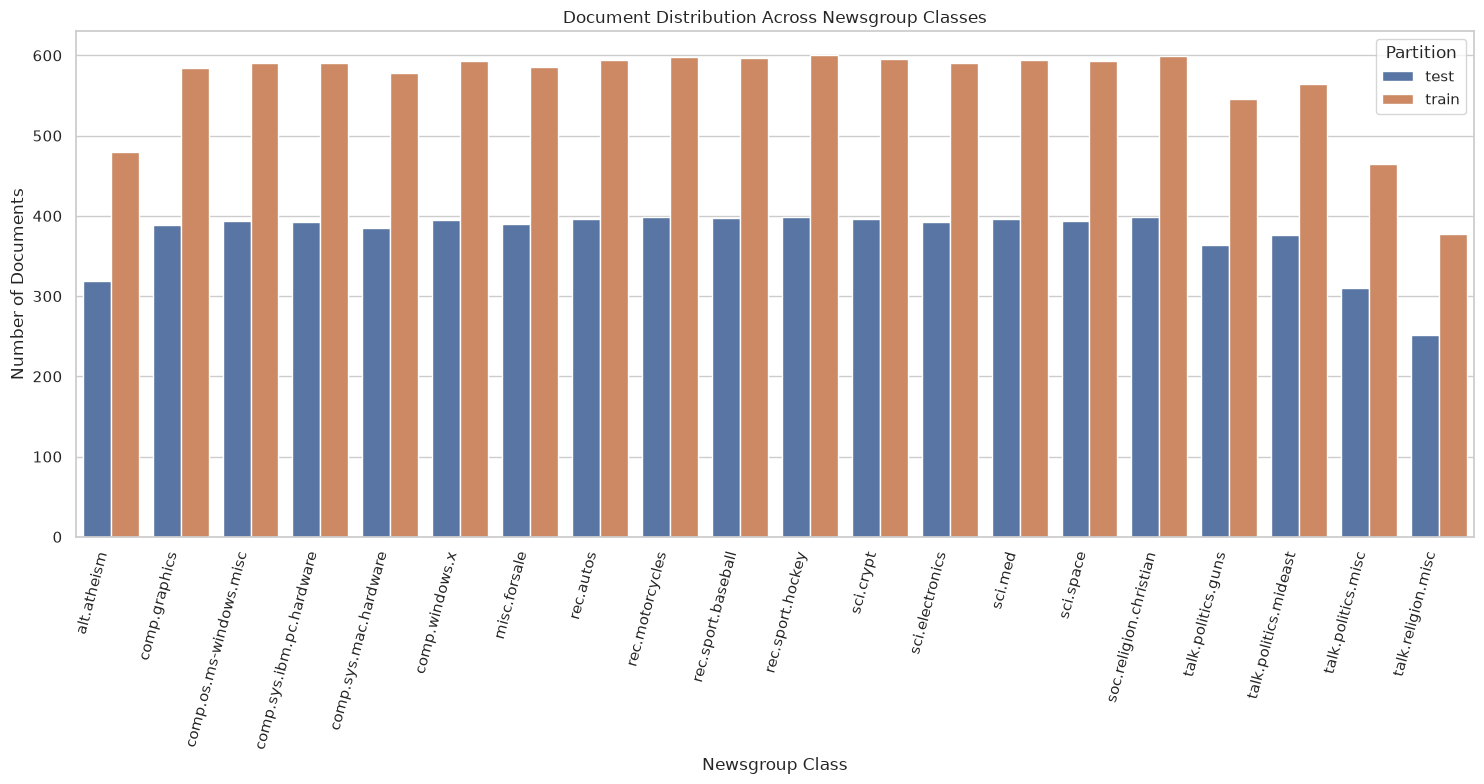

In [8]:
plot_data = (
    df.groupby(["label", "source_split"])
    .size()
    .reset_index(name="document_count")
)

plt.figure(figsize=(15, 8))

sns.barplot(
    data=plot_data,
    x="label",
    y="document_count",
    hue="source_split",
)

plt.title("Document Distribution Across Newsgroup Classes")
plt.xlabel("Newsgroup Class")
plt.ylabel("Number of Documents")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Partition")
plt.tight_layout()
plt.show()

In [9]:
train_counts = df.loc[
    df["source_split"] == "train",
    "label",
].value_counts()

test_counts = df.loc[
    df["source_split"] == "test",
    "label",
].value_counts()

imbalance_statistics = pd.DataFrame(
    {
        "training_count": train_counts,
        "test_count": test_counts,
    }
).sort_values("training_count")

imbalance_ratio = (
    train_counts.max() / train_counts.min()
)

print("Training class counts:")
display(train_counts.describe())

print("\nTest class counts:")
display(test_counts.describe())

print("\nTraining imbalance ratio:", round(imbalance_ratio, 3))

display(imbalance_statistics)

Training class counts:


count     20.000000
mean     565.700000
std       58.251813
min      377.000000
25%      574.500000
50%      591.000000
75%      594.250000
max      600.000000
Name: count, dtype: float64


Test class counts:


count     20.000000
mean     376.600000
std       38.733095
min      251.000000
25%      382.750000
50%      393.500000
75%      396.000000
max      399.000000
Name: count, dtype: float64


Training imbalance ratio: 1.592


,training_count,test_count
label,,
talk.religion.misc,377,251
talk.politics.misc,465,310
alt.atheism,480,319
talk.politics.guns,546,364
talk.politics.mideast,564,376
comp.sys.mac.hardware,578,385
comp.graphics,584,389
misc.forsale,585,390
comp.sys.ibm.pc.hardware,590,392


## 8. Document Length Analysis

Document length is examined using both character counts and word counts.

The original document contains more than just its message body in some
cases. Therefore, we distinguish between:

- Full document: the complete original text.
- Message body: text following the first blank-line separator, where
  such a separator exists.

This distinction is important because headers and other metadata may
contain information that models can exploit independently of the
underlying topic.

In [10]:
def extract_message_body(text: str) -> str:
    """Extract message body while preserving the original dataset."""
    _, separator, body = text.partition("\n\n")
    return body if separator else text


analysis_df = df[
    ["record_id", "source_split", "label", "text"]
].copy()

analysis_df["body"] = analysis_df["text"].map(
    extract_message_body
)

analysis_df["full_characters"] = (
    analysis_df["text"].str.len()
)

analysis_df["body_characters"] = (
    analysis_df["body"].str.len()
)

analysis_df["full_words"] = (
    analysis_df["text"].str.findall(r"\b\w+\b").str.len()
)

analysis_df["body_words"] = (
    analysis_df["body"].str.findall(r"\b\w+\b").str.len()
)

display(analysis_df.head())

,record_id,source_split,label,text,body,full_characters,body_characters,full_words,body_words
0,20newsgroups-train-00000,train,rec.sport.baseball,From: cubbie@garnet.berkeley.edu ( )\nSubject: Re: Cubs behind Mar...,\ngajarsky@pilot.njin.net writes:\n\nmorgan and guzman will have era's 1 run higher than last ye...,770,534,131,101
1,20newsgroups-train-00001,train,comp.sys.mac.hardware,From: gnelson@pion.rutgers.edu (Gregory Nelson)\nSubject: Thanks Apple: Free Ethernet on my C610...,"\n\tWell, I just got my Centris 610 yesterday. It took just over two \nweeks from placing the o...",1562,1360,286,251
2,20newsgroups-train-00002,train,sci.crypt,From: crypt-comments@math.ncsu.edu\nSubject: Cryptography FAQ 10/10 - References\nOrganization: ...,"Archive-name: cryptography-faq/part10\nLast-modified: 1993/4/15\n\n\nFAQ for sci.crypt, part 10:...",16199,15711,2259,2182
3,20newsgroups-train-00003,train,comp.sys.mac.hardware,From: ()\nSubject: Re: Quadra SCSI Problems???\nOrganization: Apple Computer Inc.\nLines: 28\n\...,> ATTENTION: Mac Quadra owners: Many storage industry experts have\n> concluded that Mac Quadras...,1791,1699,305,293
4,20newsgroups-train-00004,train,alt.atheism,From: keith@cco.caltech.edu (Keith Allan Schneider)\nSubject: Re: <Political Atheists?\nOrganiza...,bobbe@vice.ICO.TEK.COM (Robert Beauchaine) writes:\n\n>To show that the examples I and others\n>...,768,575,118,92


In [11]:
length_columns = [
    "full_characters",
    "body_characters",
    "full_words",
    "body_words",
]

length_statistics = analysis_df[length_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

display(length_statistics.round(2))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
full_characters,18846.0,1902.53,3984.97,115.0,751.0,1175.0,1874.75,3151.5,4698.75,13695.00,160616.0
body_characters,18846.0,1713.61,3979.15,0.0,565.0,985.0,1678.00,2956.5,4512.00,13448.05,160471.0
full_words,18846.0,317.65,764.70,18.0,121.0,190.0,311.00,526.0,781.00,2184.65,39841.0
body_words,18846.0,288.66,763.93,0.0,92.0,161.0,280.00,498.0,754.00,2157.30,39819.0


### Interpreting Document Length

The document lengths show substantial variation.

Across the 18,846 records, the median message body contains **161 words**, compared with a mean of approximately **289 words**. The mean is considerably higher because a relatively small number of documents are much longer than the typical message.

The difference between the median and mean, together with the maximum body length of 39,819 words, indicates a strongly right-skewed distribution. A small number of unusually long documents have a noticeable effect on the average. For this reason, the median and upper percentiles provide useful context alongside the mean.

Document length also varies across newsgroups. For example, `talk.politics.mideast` has the highest mean body length in the observed class-level results, at approximately 493 words. `misc.forsale` has the lowest, at approximately 133 words. These differences suggest that the classes vary not only in subject matter but also in the way participants communicate.

The full-document and message-body statistics also differ. The median full document contains 190 words, compared with 161 words in the extracted body. This illustrates that material outside the message body contributes to the text presented to a model.

The practical implication is that document length and message structure deserve attention during preprocessing. Very long messages may contain extensive quotations or unrelated discussion, while short messages may offer limited topic information. We should not assume that longer documents are necessarily more informative.

The body extraction used here is an exploratory distinction, not a final preprocessing decision. Later experiments should establish whether using the full document or a reduced message body produces more reliable classification results.

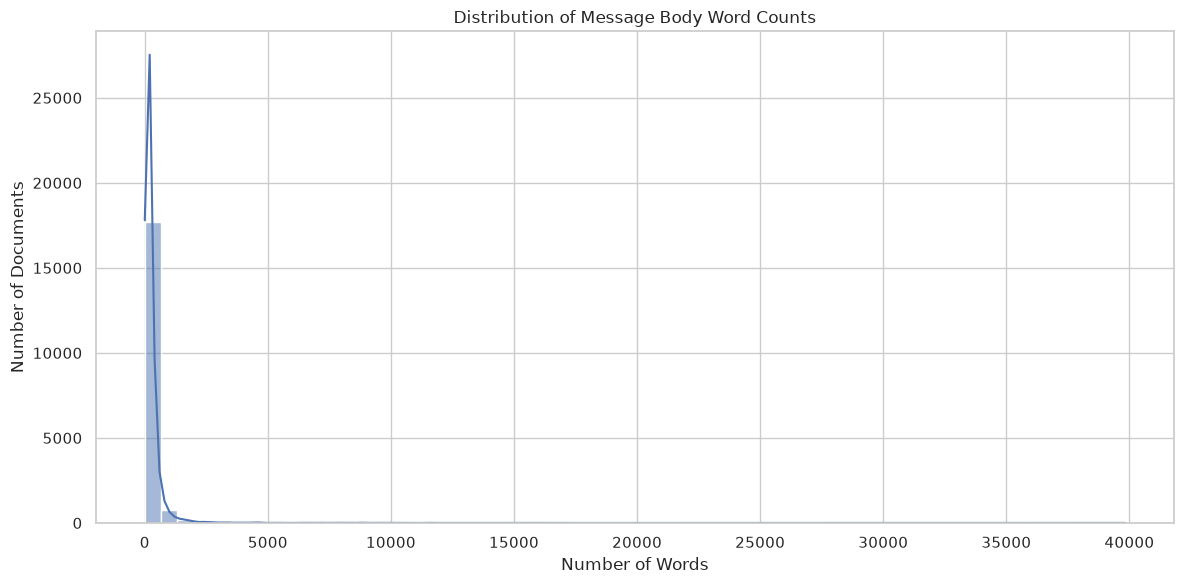

In [12]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=analysis_df,
    x="body_words",
    bins=60,
    kde=True,
)

plt.title("Distribution of Message Body Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Documents")
plt.tight_layout()
plt.show()

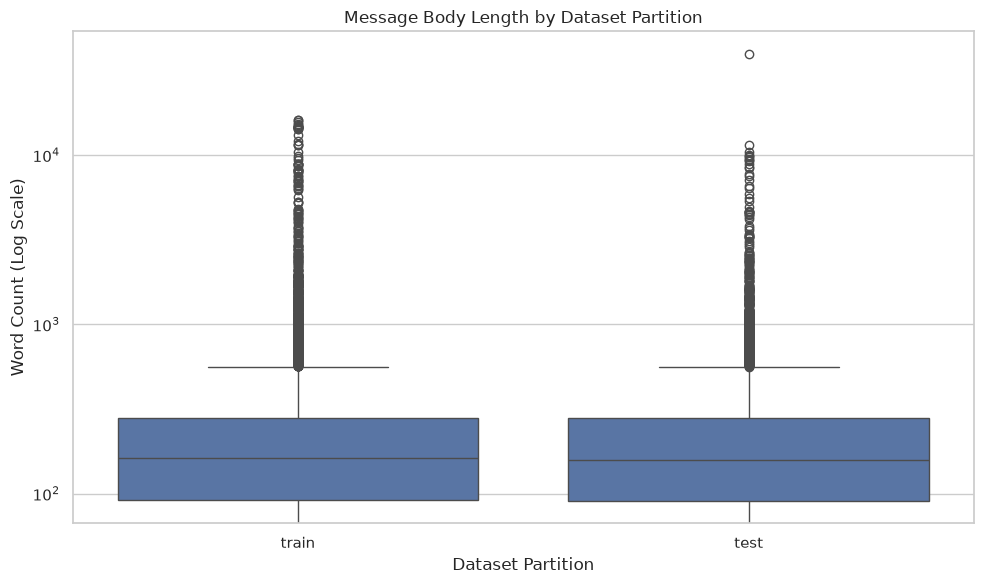

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x="source_split",
    y="body_words",
)

plt.yscale("log")
plt.title("Message Body Length by Dataset Partition")
plt.xlabel("Dataset Partition")
plt.ylabel("Word Count (Log Scale)")
plt.tight_layout()
plt.show()

,document_count,mean_words,median_words,std_words
label,,,,
talk.politics.mideast,940,492.50,271.5,863.05
comp.os.ms-windows.misc,985,484.37,135.0,2302.51
talk.politics.misc,775,428.91,234.0,807.01
soc.religion.christian,997,382.53,247.0,447.60
talk.religion.misc,628,351.21,203.0,538.99
talk.politics.guns,910,335.44,224.5,507.31
alt.atheism,799,333.76,204.0,529.87
sci.crypt,991,320.38,188.0,609.62
comp.windows.x,988,301.79,132.0,1010.86


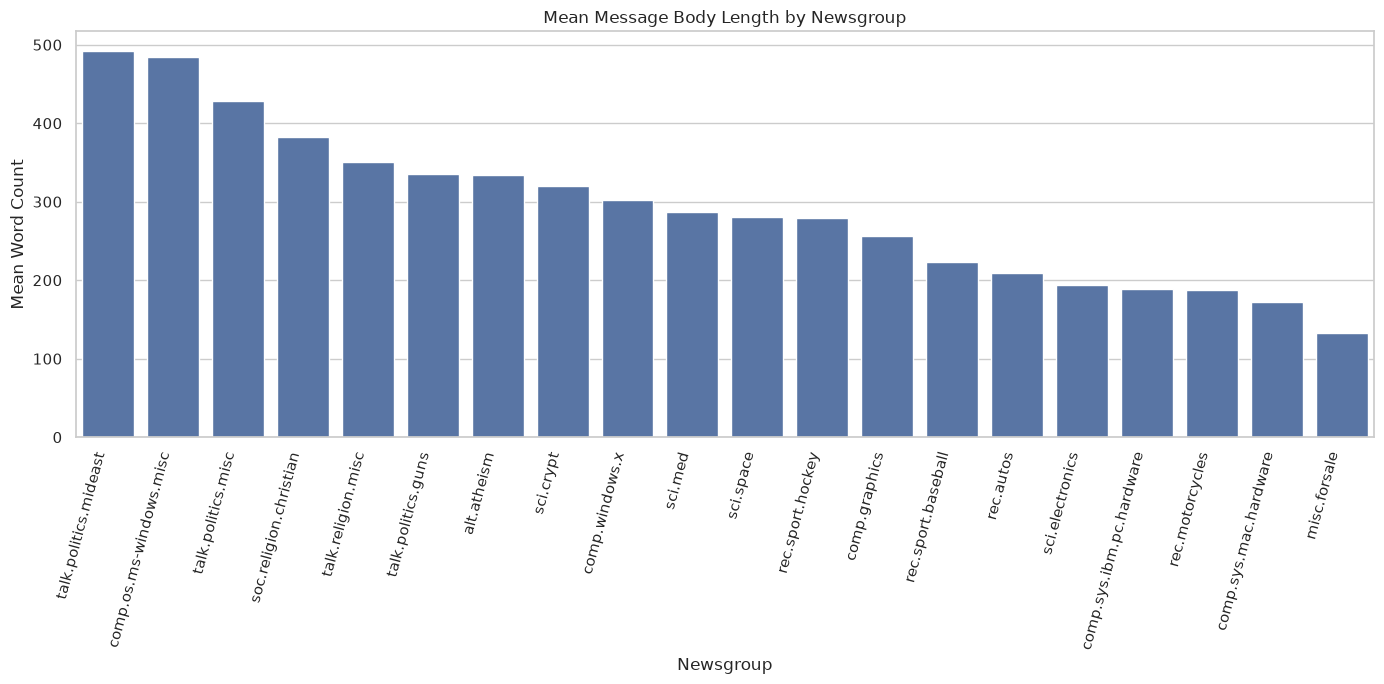

In [14]:
class_length_statistics = (
    analysis_df.groupby("label")
    .agg(
        document_count=("record_id", "count"),
        mean_words=("body_words", "mean"),
        median_words=("body_words", "median"),
        std_words=("body_words", "std"),
    )
    .sort_values("mean_words", ascending=False)
)

display(class_length_statistics.round(2))

plt.figure(figsize=(14, 7))

sns.barplot(
    data=class_length_statistics.reset_index(),
    x="label",
    y="mean_words",
)

plt.title("Mean Message Body Length by Newsgroup")
plt.xlabel("Newsgroup")
plt.ylabel("Mean Word Count")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 9. Vocabulary Analysis

This section examines the vocabulary present in the message bodies.

A simple tokenizer is used to identify word-like tokens. The analysis
includes:

- Total token occurrences.
- Number of unique tokens.
- Most frequently occurring tokens.
- Document frequency.
- Hapax legomena (tokens occurring only once in the corpus).

No stop-word removal, stemming, lemmatization, or feature selection is
performed.

These results provide a baseline understanding of the lexical
characteristics of the corpus.

In [16]:
TOKEN_PATTERN = re.compile(r"\b[a-zA-Z0-9_]+\b")


def tokenize(text: str) -> list[str]:
    """Produce simple lowercase word-like tokens."""
    return TOKEN_PATTERN.findall(text.lower())


analysis_df["tokens"] = analysis_df["body"].map(tokenize)

analysis_df["token_count"] = (
    analysis_df["tokens"].str.len()
)

print("Total token occurrences:", analysis_df["token_count"].sum())

vocabulary_counter = Counter(
    token
    for tokens in analysis_df["tokens"]
    for token in tokens
)

print("Unique vocabulary terms:", len(vocabulary_counter))
print("Total token occurrences:", sum(vocabulary_counter.values()))

Total token occurrences: 5439974
Unique vocabulary terms: 167405
Total token occurrences: 5439974


### Interpreting the Vocabulary Findings

The exploratory tokenizer identified approximately **5.44 million token occurrences and 167,405 unique terms** across the message bodies.

Of the unique terms, 86,935 occur only once. This represents approximately **51.9% of the observed vocabulary**. In other words, more than half of the unique terms are rare within this corpus.

This is an important characteristic for text classification. A large vocabulary can provide useful topic-specific information, but it can also create sparse feature representations. Many terms will occur in only a small number of documents, making them less useful as general indicators of a class.

The most frequent terms include ordinary English words such as `the`, `to`, `of`, and `a`. Their high frequency is expected in natural language, but their presence across many classes means that frequency alone does not make them useful for distinguishing topics.

The results also reveal some limitations of the simple tokenizer. For example, tokens such as `s` and `t` appear frequently. These can arise when apostrophes and contractions are split into separate tokens. The term `writes` is also prominent, which may reflect recurring quoted-reply conventions in discussion messages. The unusually frequent `ax` token deserves further inspection rather than being assigned a meaning without evidence.

These observations support several experiments rather than one predetermined preprocessing strategy:

- Compare raw token counts with TF-IDF weighting.
- Compare unigram features with unigram-and-bigram features.
- Evaluate stop-word removal rather than assuming it always improves performance.
- Investigate vocabulary limits and minimum document-frequency thresholds.
- Consider whether a more suitable tokenizer improves the representation of contractions and technical terms.

One distinction is important here: **term frequency** counts how often a term occurs, while **document frequency** counts how many documents contain it. Both are useful, but they answer different questions. TF-IDF uses this distinction to reduce the influence of terms that occur in many documents.

The vocabulary analysis is exploratory. Its tokenizer is deliberately simple and should not be mistaken for the final feature-extraction pipeline.

,term,frequency
0,the,237168
1,to,119329
2,of,106134
3,a,103563
4,and,93699
5,i,86112
6,in,79789
7,is,69172
8,that,64881
9,ax,62410


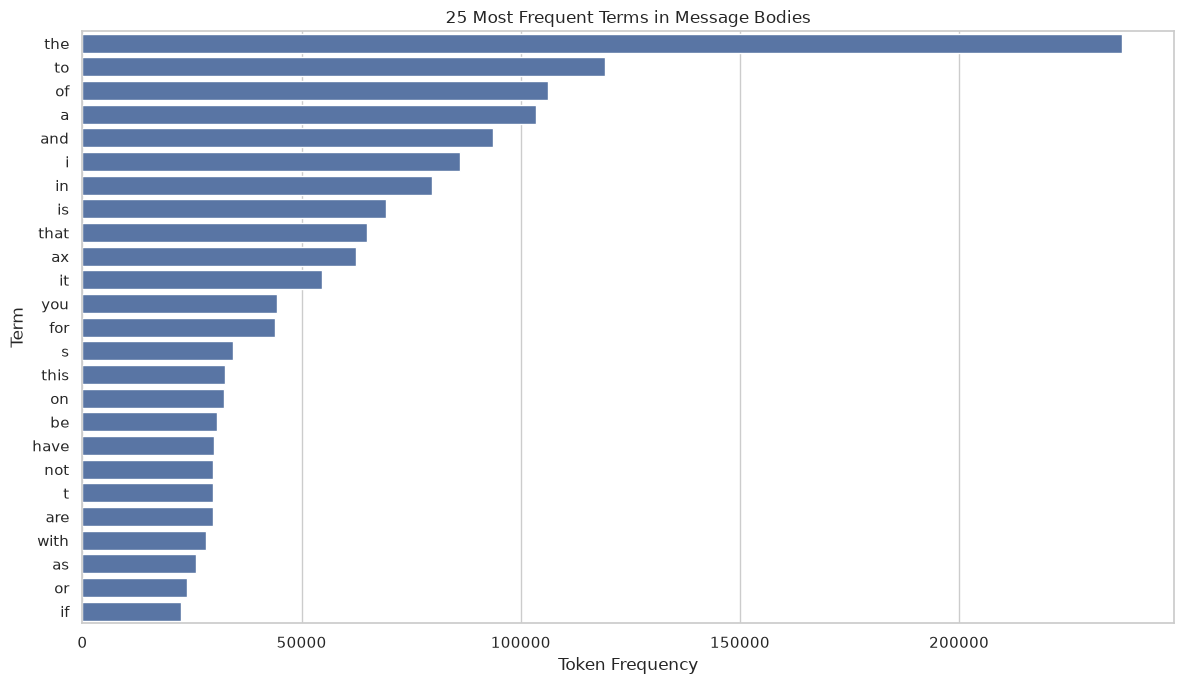

In [17]:
top_terms = pd.DataFrame(
    vocabulary_counter.most_common(25),
    columns=["term", "frequency"],
)

display(top_terms)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_terms,
    x="frequency",
    y="term",
)

plt.title("25 Most Frequent Terms in Message Bodies")
plt.xlabel("Token Frequency")
plt.ylabel("Term")
plt.tight_layout()
plt.show()

In [18]:
document_frequency = Counter()

for tokens in analysis_df["tokens"]:
    document_frequency.update(set(tokens))

document_frequency_df = pd.DataFrame(
    document_frequency.most_common(25),
    columns=["term", "document_frequency"],
)

hapax_count = sum(
    1 for frequency in vocabulary_counter.values()
    if frequency == 1
)

lexical_summary = {
    "total_token_occurrences": sum(vocabulary_counter.values()),
    "unique_vocabulary_terms": len(vocabulary_counter),
    "hapax_legomena": hapax_count,
    "hapax_percentage": (
        hapax_count / len(vocabulary_counter) * 100
        if vocabulary_counter
        else 0
    ),
}

print("Lexical summary:")
display(pd.Series(lexical_summary).to_frame("value"))

print("Most widely distributed terms:")
display(document_frequency_df)

Lexical summary:


,value
total_token_occurrences,5.439974e+06
unique_vocabulary_terms,1.674050e+05
hapax_legomena,8.693500e+04
hapax_percentage,5.193095e+01


Most widely distributed terms:


,term,document_frequency
0,the,17436
1,a,16355
2,to,16326
3,in,15727
4,i,15698
5,and,15438
6,of,15425
7,is,14193
8,it,13372
9,that,13314


## 10. Representative Document Inspection

Representative documents are sampled from each newsgroup to provide
qualitative insight into the corpus.

The purpose is to identify:

- Topic-specific terminology.
- Differences in writing style.
- Informal language and abbreviations.
- Technical terminology.
- Quoted messages and signatures.
- Potentially informative metadata.

Sampling is deterministic to ensure reproducibility.

In [25]:
representative_samples = (
    analysis_df.groupby("label", group_keys=False)
    .sample(n=1, random_state=RANDOM_SEED)
    .sort_values("label")
)

for _, row in representative_samples.iterrows():
    print("=" * 90)
    print("CLASS:", row["label"])
    print("RECORD:", row["record_id"])
    print("PARTITION:", row["source_split"])
    print("BODY WORD COUNT:", row["body_words"])
    print("\nDOCUMENT PREVIEW:")
    preview = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[email redacted]",
        row["body"][:600],
    )
    print(preview)
    print()

CLASS: alt.atheism
RECORD: 20newsgroups-test-05153
PARTITION: test
BODY WORD COUNT: 401

DOCUMENT PREVIEW:
In article <[email redacted]>, [email redacted] (Mike Cobb) writes:
> I guess I'm delving into a religious language area.  What exactly is morality 
> or morals?  

I hope there is not one- with a subject like this you just have a spiral.  What
would then be a morality of a morality of morals.  Labels don't make arguments. 
One really needs a solid measuring stick by which most actions can be
interpreted, even though this would hardly seem moral.  For example "The best
thing for me is to ensure that I will eat and drink enough.  Hence all actions
must be weighed against thi

CLASS: comp.graphics
RECORD: 20newsgroups-train-10966
PARTITION: train
BODY WORD COUNT: 122

DOCUMENT PREVIEW:
Martin Preston ([email redacted]) wrote:
: In <[email redacted]> [email redacted] (Allen B) writes:
: 
: >I've got the 6.0 spec (obviously since I quoted it in my last posting). 
: >My gripe about TIF

### What the Representative Documents Reveal

The sampled messages provide useful context that numerical summaries cannot capture on their own.

The corpus contains conversational writing rather than uniformly structured articles. Messages include replies to earlier discussions, quoted passages, informal expressions, technical terminology, and references to other participants.

This matters because a classifier does not automatically distinguish between the author's own contribution and text quoted from someone else. A message posted in one newsgroup may contain substantial material from an earlier discussion, potentially introducing vocabulary associated with another topic.

The samples also demonstrate why the newsgroup labels should be interpreted carefully. They identify the discussion group to which a message was assigned; they do not guarantee that every message discusses only one topic.

These observations make metadata handling and quoted-text treatment important experimental decisions. Removing headers or quoted material may reduce unwanted signals, but it may also remove information that genuinely helps distinguish classes. We should therefore compare these approaches empirically rather than assume that more aggressive cleaning is always better.

The displayed samples are illustrative, not a statistically representative assessment of every document in their respective classes.

### Qualitative Observations

After reviewing the sampled documents, record observations about:

1. Whether documents within a class share recognizable terminology.
2. Whether writing styles differ between classes.
3. Whether messages contain irrelevant or repetitive material.
4. Whether headers, signatures, or quoted replies may introduce
   unintended classification signals.
5. Whether some documents are too short or ambiguous to provide
   meaningful topic information.

These observations will inform the preprocessing experiments.

## 11. Dataset Integrity and Train-Test Contamination

Dataset integrity is essential for reliable evaluation.

The original dataset was subjected to:

1. Structural validation.
2. Exact duplicate analysis.
3. Approximate near-duplicate analysis using MinHash and locality-
   sensitive hashing.
4. Normalized exact message-body duplicate analysis.
5. Cross-partition overlap inspection.

The official training and test partitions remain unchanged.

The contamination manifests define additional sensitivity analyses.
They do not replace the official benchmark.

In [20]:
with LEAKAGE_REPORT_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    leakage_report = json.load(file)

with BODY_AUDIT_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    body_audit = json.load(file)

with CONTAMINATION_MANIFEST_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    contamination_manifest = json.load(file)

print("Audit reports loaded successfully.")

Audit reports loaded successfully.


In [24]:
body_audit_summary = body_audit.get("analysis", {})

if not body_audit_summary:
    raise ValueError(
        "The body audit report does not contain the expected 'analysis' summary."
    )

print("Normalized exact-body duplicate audit:")
display(
    pd.Series(body_audit_summary, name="value").to_frame()
)

Normalized exact-body duplicate audit:


,value
method,normalized_exact_document_body_sha256
normalization,"[Unicode NFKC, case folding, whitespace normalization]"
original_records_modified,False
records_analyzed,18846
duplicate_group_count,61
duplicate_document_count,126
cross_partition_duplicate_group_count,11
cross_partition_duplicate_document_count,25
conflicting_label_group_count,11
cross_partition_conflicting_label_group_count,2


In [22]:
contamination_summary = contamination_manifest["summary"]

print("Contamination manifest summary:")
display(
    pd.Series(contamination_summary, name="value").to_frame()
)

print("\nEvaluation tracks:")
for track_name, track_details in (
    contamination_manifest["evaluation_tracks"].items()
):
    print(f"\n{track_name}")
    print(json.dumps(track_details, indent=2))

Contamination manifest summary:


,value
substantive_cross_partition_exact_duplicate_groups,10
substantive_training_documents_implicated,10
substantive_test_documents_implicated,13
trivial_cross_partition_exact_duplicate_groups,1
cross_partition_near_duplicate_pairs_not_excluded,31
clean_test_document_count,7519
decontaminated_training_document_count,11304



Evaluation tracks:

official_benchmark
{
  "training": "Original official training partition.",
  "evaluation": "Original official test partition.",
  "exclusions": []
}

clean_test_sensitivity
{
  "training": "Original official training partition.",
  "evaluation": "Official test partition excluding test documents with substantive exact-body duplicates in training.",
  "excluded_test_record_ids": [
    "20newsgroups-test-00375",
    "20newsgroups-test-00523",
    "20newsgroups-test-00771",
    "20newsgroups-test-01544",
    "20newsgroups-test-02069",
    "20newsgroups-test-02663",
    "20newsgroups-test-02673",
    "20newsgroups-test-02882",
    "20newsgroups-test-03660",
    "20newsgroups-test-03930",
    "20newsgroups-test-04933",
    "20newsgroups-test-05144",
    "20newsgroups-test-05731"
  ]
}

decontaminated_training_sensitivity
{
  "training": "Official training partition excluding training documents with substantive exact-body duplicates in the official test partition.",
  "e

In [23]:
duplicate_analysis = leakage_report.get(
    "duplicate_analysis",
    {},
)

near_duplicate_pairs = duplicate_analysis.get(
    "near_duplicate_pairs",
    [],
)

cross_partition_pairs = [
    pair
    for pair in near_duplicate_pairs
    if pair.get("cross_partition") is True
]

print("Total near-duplicate pairs:", len(near_duplicate_pairs))
print(
    "Cross-partition near-duplicate pairs:",
    len(cross_partition_pairs),
)

if cross_partition_pairs:
    display(pd.DataFrame(cross_partition_pairs).head(15))

Total near-duplicate pairs: 174
Cross-partition near-duplicate pairs: 31


,left_record_id,right_record_id,left_partition,right_partition,left_label,right_label,jaccard_similarity,cross_partition,label_agreement
0,20newsgroups-train-01086,20newsgroups-test-02663,train,test,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,1.000000,True,False
1,20newsgroups-train-01086,20newsgroups-test-05731,train,test,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,1.000000,True,False
2,20newsgroups-train-01215,20newsgroups-test-00523,train,test,misc.forsale,misc.forsale,1.000000,True,True
3,20newsgroups-train-01748,20newsgroups-test-02673,train,test,misc.forsale,misc.forsale,1.000000,True,True
4,20newsgroups-train-01943,20newsgroups-test-00771,train,test,misc.forsale,misc.forsale,1.000000,True,True
5,20newsgroups-train-01976,20newsgroups-test-03930,train,test,comp.graphics,comp.graphics,1.000000,True,True
6,20newsgroups-train-03947,20newsgroups-test-00375,train,test,misc.forsale,misc.forsale,1.000000,True,True
7,20newsgroups-train-03956,20newsgroups-test-04933,train,test,sci.med,sci.med,1.000000,True,True
8,20newsgroups-train-08708,20newsgroups-test-01544,train,test,misc.forsale,misc.forsale,1.000000,True,True
9,20newsgroups-train-08708,20newsgroups-test-02069,train,test,misc.forsale,misc.forsale,1.000000,True,True


### Interpretation of Dataset Integrity Findings

The content-overlap analysis identified an important consideration for the reliability of the benchmark evaluation.

The normalized exact-body audit identified 11 duplicate groups spanning the official training and test partitions. Ten contained substantive message bodies, while one contained only the single word `test`.

The ten substantive groups involved 10 training documents and 13 test documents. Nine groups had matching class labels. One group contained the same substantive message body under two different newsgroup labels, consistent with the cross-posting observed during manual inspection.

This distinction matters. An identical message appearing under different newsgroup labels is not necessarily a labelling error. The newsgroup represents the destination of a discussion message, and a message can legitimately be posted to more than one group. Nevertheless, identical content across training and test partitions can make an evaluation less independent of the training data.

The approximate near-duplicate analysis identified 31 cross-partition pairs. These pairs were not automatically excluded. Similarity based on word shingles is useful for finding candidates, but it does not establish that two documents are exact duplicates or that they should be removed. They remain a separate issue for interpretation and possible further investigation.

Three evaluation tracks have therefore been retained:

1. **Official benchmark:** the original training and test partitions, without exclusions.
2. **Clean-test sensitivity:** the original training partition evaluated against the test partition after removing the 13 test documents implicated in substantive exact-body duplication.
3. **Decontaminated-training sensitivity:** the training partition after removing the 10 implicated training documents, evaluated against the original test partition.

These tracks answer slightly different questions. The official benchmark preserves comparability with the published dataset split. The two sensitivity evaluations help establish whether the identified exact-content overlap materially affects measured performance.

The original raw dataset has not been modified, deleted, or relabelled. The exclusions are recorded separately in reproducible manifests.

## 12. Exploratory Findings and Conclusions

### 12.1 Dataset Structure

The primary benchmark contains 18,846 documents distributed across 20 newsgroup classes. It retains the original training partition of 11,314 documents and test partition of 7,532 documents.

The structural checks found no missing values in the dataset fields and no duplicate record identifiers. The dataset is therefore structurally suitable for the next stage of supervised classification experiments.

### 12.2 Class Distribution

The classes are relatively balanced, with training counts ranging from 377 to 600 documents. The largest-to-smallest training class ratio is approximately 1.59:1.

The test partition follows a comparable distribution. This reduces concern about severe class imbalance at the dataset level, although per-class performance must still be examined during model evaluation.

Macro-averaged F1 and class-level precision and recall will help establish whether performance is consistent across all 20 classes.

### 12.3 Document Length

Message lengths vary considerably. The median message body contains 161 words, while the mean is approximately 289 words. The large difference indicates a right-skewed distribution, with a small number of very long messages influencing the mean.

There are also noticeable differences in average message length across newsgroups. This suggests that document length may be associated with the discussion context and should be considered when comparing feature representations and preprocessing approaches.

The distinction between full documents and extracted message bodies is particularly important because headers and other message structure may contribute information that is not part of the author's main discussion.

### 12.4 Vocabulary Characteristics

The simple exploratory tokenizer identified approximately 167,405 unique terms from 5.44 million token occurrences. Approximately 51.9% of the unique terms occurred only once.

This indicates a large and relatively sparse vocabulary. Common English words dominate the most frequent terms, while a substantial number of terms occur infrequently.

The findings justify investigating TF-IDF weighting, n-gram features, vocabulary thresholds, and alternative preprocessing strategies. They do not establish in advance which representation will perform best.

### 12.5 Dataset Quality and Evaluation Reliability

The integrity analysis found substantive exact-body duplication across the official training and test partitions. It also identified approximate near-duplicate pairs that warrant separate consideration.

The findings do not invalidate the dataset. They do, however, mean that evaluation results should be interpreted with awareness of content overlap.

The official benchmark will remain the primary reference point. The clean-test and decontaminated-training evaluations will provide additional evidence about the effect of the identified exact duplicates.

The dataset's discussion-group labels also require careful interpretation. Cross-posting and quoted replies can produce messages containing content associated with more than one class. This is a characteristic of the source data, not necessarily an annotation mistake.

### 12.6 Implications for Subsequent Experiments

The exploration identifies several decisions that should be evaluated experimentally:

- **Document representation:** compare complete original messages with reduced message bodies.
- **Feature extraction:** compare Bag-of-Words and TF-IDF representations.
- **Contextual features:** compare unigram features with unigram-and-bigram features.
- **Preprocessing:** evaluate stop-word removal, tokenization choices, and other text normalization strategies.
- **Vocabulary control:** investigate minimum document frequency and maximum vocabulary size.
- **Evaluation:** report accuracy, macro-F1, weighted-F1, and per-class metrics.
- **Data integrity:** compare official benchmark performance with the two contamination sensitivity evaluations.

These decisions will be made using training and validation data. The official test partition must remain outside model selection and hyperparameter tuning.

### 12.7 Conclusion

The 20 Newsgroups corpus provides a suitable primary benchmark for the TopicSense-NLP supervised multi-class classification project. It contains a substantial number of labelled documents, covers 20 discussion categories, and provides established training and test partitions.

The exploration has also highlighted characteristics that will influence model development: varied document lengths, a large vocabulary, conversational writing, message metadata, quoted content, and a limited amount of exact-content overlap between partitions.

Rather than treating these characteristics as reasons to apply aggressive preprocessing, the project will evaluate their effects systematically. The original dataset and its official partitions remain preserved, while separate manifests support contamination sensitivity analysis.

The next stage develops the preprocessing pipeline and establishes consistent text representations for the classical machine-learning experiments.